# ۱۲ · ساخت Autoencoder با Conv2D و Conv2DTranspose

یک تصویر MNIST را کوچک و دوباره بازسازی می‌کنیم. هر دو پیاده‌سازی TensorFlow و PyTorch از صفر آموزش می‌بینند.
بعد از بازسازی معمولی، با همان معماری یک مثال سادهٔ حذف نویز نیز انجام می‌دهیم.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


## ۱. Autoencoder چه کاری انجام می‌دهد؟

Encoder تصویر را به نمایش کوچک‌تر تبدیل می‌کند و Decoder از آن تصویر بازسازی‌شده می‌سازد:

$$z=Encoder(x),\qquad \hat x=Decoder(z).$$

هدف آموزشی همان تصویر ورودی است؛ برای آموزش به برچسب رقم نیاز نداریم.
با کوچک‌کردن نمایش میانی یا محدودکردن شبکه، مدل مجبور می‌شود اطلاعات مفید را نگه دارد.
بازسازی دقیق یا یادگیری مفهوم واقعی رقم تضمین نمی‌شود؛ شبکه ممکن است بعضی جزئیات را از دست بدهد.

In [2]:
from pathlib import Path
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
root=Path.cwd()
if root.name=='notebooks': root=root.parent
with np.load(root/'data'/'mnist.npz') as data:
    raw=data['x_train'].astype('float32')/255.
    test=data['x_test'].astype('float32')/255.
    digit_labels=data['y_test'][:2000]
x_train=raw[:10000]; x_val=raw[50000:52000]; x_test=test[:2000]
print('Train/validation/test:',x_train.shape,x_val.shape,x_test.shape)
print('TF input:',x_train[...,None].shape,'Torch input:',x_train[:,None].shape)

Train/validation/test: (10000, 28, 28) (2000, 28, 28) (2000, 28, 28)
TF input: (10000, 28, 28, 1) Torch input: (10000, 1, 28, 28)


## ۲. مسیر شکل داده

| مرحله | اندازهٔ مکانی | کانال |
|---|---|---|
| ورودی | 28×28 | 1 |
| Encoder Conv stride=2 | 14×14 | 16 |
| Encoder Conv stride=2 | 7×7 | 8 |
| Decoder ConvTranspose stride=2 | 14×14 | 16 |
| Decoder ConvTranspose stride=2 | 28×28 | 1 |

نمایش نهفتهٔ هر تصویر ۷×۷×۸=۳۹۲ عدد دارد؛ ورودی ۷۸۴ عدد داشت. این مقایسه تعداد عددهاست، نه لزوماً اندازهٔ فایل فشرده.
وزن‌های شبکه هم حافظه می‌گیرند. یک لایهٔ کانولوشنی با stride=2 اندازه را کم می‌کند.

## ۳. Conv2DTranspose معکوس واقعی Conv نیست

اگر Conv را به صورت عمل خطی $y=Ax$ بنویسیم، عمل ترانهاده با $A^T$ مرتبط است، نه لزوماً $A^{-1}$.
پارامترهای Decoder آموخته می‌شوند تا اطلاعات میانی را به تصویر تبدیل کنند.
برای PyTorch با کرنل ۴، stride برابر ۲ و padding برابر ۱:

$$H_{out}=(H_{in}-1)\times2-2+4=2H_{in}.$$

پس ۷ به ۱۴ و ۱۴ به ۲۸ می‌رسد. این انتخاب کرنل همپوشانی یکنواخت‌تری دارد، ولی همهٔ artefactها را تضمینی حذف نمی‌کند.

In [3]:
encoder_tf=tf.keras.Sequential([
    tf.keras.layers.Input((28,28,1)),
    tf.keras.layers.Conv2D(16,3,strides=2,padding='same',activation='relu'),
    tf.keras.layers.Conv2D(8,3,strides=2,padding='same',activation='relu')
],name='encoder')
decoder_tf=tf.keras.Sequential([
    tf.keras.layers.Input((7,7,8)),
    tf.keras.layers.Conv2DTranspose(16,4,strides=2,padding='same',activation='relu'),
    tf.keras.layers.Conv2DTranspose(1,4,strides=2,padding='same',activation='sigmoid')
],name='decoder')
autoencoder_tf=tf.keras.Sequential([encoder_tf,decoder_tf])
autoencoder_tf.compile(optimizer='adam',loss='mse')
encoder_tf.summary(); decoder_tf.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 8)        │         1,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,320 (5.16 KB)

 Trainable params: 1,320 (5.16 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_transpose                │ (None, 14, 14, 16)     │         2,064 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │           257 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,321 (9.07 KB)

 Trainable params: 2,321 (9.07 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
encoder_pt=nn.Sequential(
    nn.Conv2d(1,16,3,stride=2,padding=1),nn.ReLU(),
    nn.Conv2d(16,8,3,stride=2,padding=1),nn.ReLU())
decoder_pt=nn.Sequential(
    nn.ConvTranspose2d(8,16,4,stride=2,padding=1),nn.ReLU(),
    nn.ConvTranspose2d(16,1,4,stride=2,padding=1),nn.Sigmoid())
autoencoder_pt=nn.Sequential(encoder_pt,decoder_pt)
print(autoencoder_pt)
example=torch.from_numpy(x_train[:2,None])
with torch.no_grad():
    latent=encoder_pt(example); reconstruction=decoder_pt(latent)
print('Torch shapes:',example.shape,'→',latent.shape,'→',reconstruction.shape)
print('TF shapes:',encoder_tf.output_shape,'→',decoder_tf.output_shape)

Sequential(
  (0): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
  )
  (1): Sequential(
    (0): ConvTranspose2d(8, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(16, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): Sigmoid()
  )
)
Torch shapes: torch.Size([2, 1, 28, 28]) → torch.Size([2, 8, 7, 7]) → torch.Size([2, 1, 28, 28])
TF shapes: (None, 7, 7, 8) → (None, 28, 28, 1)


## ۴. تابع خطا و خروجی Sigmoid

$$MSE=\frac1{BHW}\sum_{b,h,w}(x_{b,h,w}-\hat x_{b,h,w})^2.$$

چون ورودی بین صفر و یک است، خروجی Sigmoid هم بین صفر و یک قرار می‌گیرد.
MSE خطای شدت پیکسل را کم می‌کند. این معیار به تنهایی کیفیت ادراکی تصویر را کامل اندازه نمی‌گیرد.
در این مسئله خروجی یک تصویر است و argmax یا accuracy طبقه‌بندی مناسب نیست.

In [5]:
history_tf=autoencoder_tf.fit(x_train[...,None],x_train[...,None],
    validation_data=(x_val[...,None],x_val[...,None]),epochs=3,batch_size=128,verbose=2)

Epoch 1/3


79/79 - 3s - 36ms/step - loss: 0.1789 - val_loss: 0.1025


Epoch 2/3


79/79 - 1s - 14ms/step - loss: 0.0623 - val_loss: 0.0317


Epoch 3/3


79/79 - 1s - 16ms/step - loss: 0.0185 - val_loss: 0.0124


## ۵. آموزش PyTorch

هر زوج داده شامل ورودی و تصویر هدف است. در مرحلهٔ بازسازی معمولی این دو یکسان‌اند.
تابع کوتاه زیر فقط همین Autoencoder را با MSE آموزش می‌دهد؛ train و validation جدا هستند.

In [6]:
def train_autoencoder(model,inputs,targets,val_inputs,val_targets,epochs=3):
    loader=DataLoader(TensorDataset(torch.from_numpy(inputs[:,None]),torch.from_numpy(targets[:,None])),batch_size=128,shuffle=True)
    optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
    history={'loss':[],'val_loss':[]}
    for epoch in range(epochs):
        model.train(); total=0.
        for xb,yb in loader:
            optimizer.zero_grad(); loss=nn.functional.mse_loss(model(xb),yb)
            loss.backward(); optimizer.step(); total+=loss.item()*len(xb)
        model.eval()
        with torch.no_grad():
            validation=nn.functional.mse_loss(model(torch.from_numpy(val_inputs[:,None])),torch.from_numpy(val_targets[:,None])).item()
        history['loss'].append(total/len(inputs)); history['val_loss'].append(validation)
        print(f'Epoch {epoch+1}: train MSE={total/len(inputs):.5f}, validation MSE={validation:.5f}')
    return history
history_pt=train_autoencoder(autoencoder_pt,x_train,x_train,x_val,x_val)

Epoch 1: train MSE=0.16721, validation MSE=0.09372


Epoch 2: train MSE=0.06065, validation MSE=0.03936


Epoch 3: train MSE=0.02654, validation MSE=0.01602


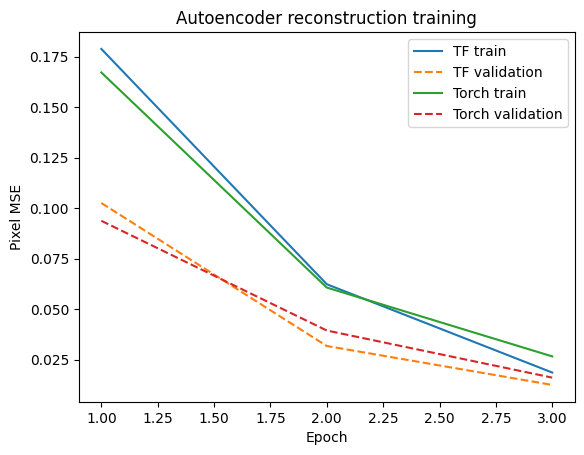

In [7]:
for name,h in [('TF',history_tf.history),('Torch',history_pt)]:
    plt.plot([1,2,3],h['loss'],label=name+' train')
    plt.plot([1,2,3],h['val_loss'],'--',label=name+' validation')
plt.xlabel('Epoch'); plt.ylabel('Pixel MSE'); plt.title('Autoencoder reconstruction training'); plt.legend(); plt.show()

## ۶. بازسازی روی دادهٔ test

هر تصویر test برای اولین بار در ارزیابی دیده می‌شود. برای مقایسه، تصویر اصلی و هر دو بازسازی را کنار هم رسم می‌کنیم.
در این درس وزن آخرین epoch گزارش می‌شود؛ هیچ انتخابی بر اساس test انجام نمی‌دهیم.

TF test MSE: 0.012361309
Torch test MSE: 0.015905207


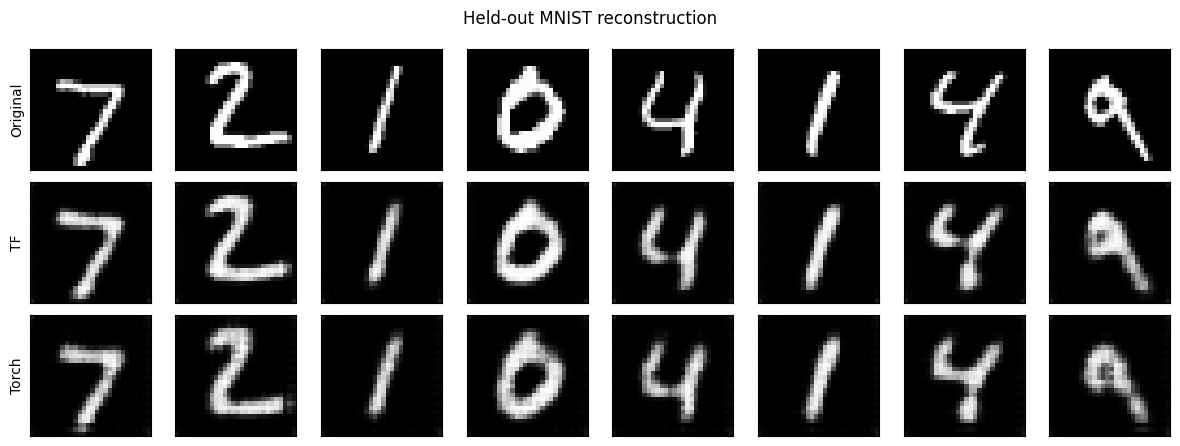

In [8]:
recon_tf=autoencoder_tf.predict(x_test[...,None],batch_size=128,verbose=0)[...,0]
autoencoder_pt.eval()
with torch.no_grad(): recon_pt=autoencoder_pt(torch.from_numpy(x_test[:,None])).numpy()[:,0]
print('TF test MSE:',np.mean((x_test-recon_tf)**2))
print('Torch test MSE:',np.mean((x_test-recon_pt)**2))
fig,axes=plt.subplots(3,8,figsize=(12,4.5))
for row,(name,images) in enumerate([('Original',x_test),('TF',recon_tf),('Torch',recon_pt)]):
    for i in range(8):
        axes[row,i].imshow(images[i],cmap='gray',vmin=0,vmax=1)
        axes[row,i].set_xticks([]); axes[row,i].set_yticks([])
    axes[row,0].set_ylabel(name)
plt.suptitle('Held-out MNIST reconstruction'); plt.tight_layout(); plt.show()

## ۷. دیدن نمایش میانی و خطای پیکسل

نمایش ۷×۷×۸ شامل هشت نقشهٔ کوچک است. هر کانال شدت پاسخ یک ویژگی آموخته‌شده را نشان می‌دهد.
این نقشه‌ها خودشان تصویر رقم یا توضیح کامل معنای آن نیستند.

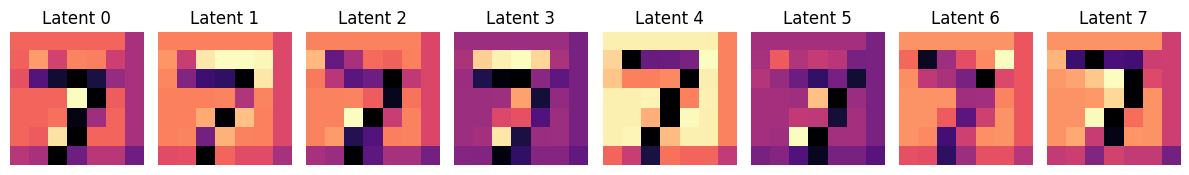

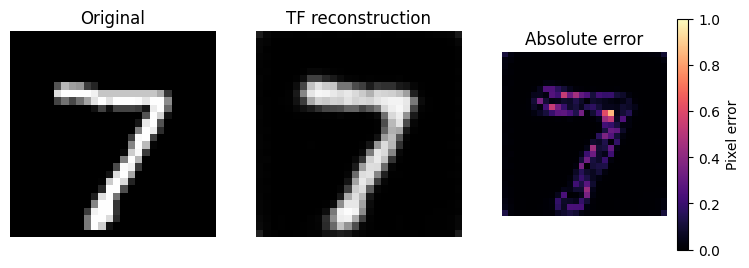

In [9]:
latent_tf=encoder_tf.predict(x_test[:1,...,None],verbose=0)[0]
fig,axes=plt.subplots(1,8,figsize=(12,2))
for i,ax in enumerate(axes):
    ax.imshow(latent_tf[:,:,i],cmap='magma'); ax.set_title('Latent '+str(i)); ax.axis('off')
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(9,3))
for ax,image,title in zip(axes,[x_test[0],recon_tf[0],np.abs(x_test[0]-recon_tf[0])],['Original','TF reconstruction','Absolute error']):
    im=ax.imshow(image,cmap='gray' if title!='Absolute error' else 'magma',vmin=0,vmax=1)
    ax.set_title(title); ax.axis('off')
fig.colorbar(im,ax=axes[-1],label='Pixel error'); plt.show()

## ۸. Denoising Autoencoder؛ همان شبکه با هدف متفاوت

اکنون ورودی را نویزی و هدف را تصویر تمیز می‌گذاریم: noisy → clean.
مدل‌های قبلی را دو epoch دیگر با این هدف آموزش می‌دهیم. اگر هدف هم نویزی باشد، مدل یاد نمی‌گیرد الزاماً نویز را حذف کند.
نویز مصنوعی Gaussian با انحراف معیار ۰٫۳ است و نتیجه به بازهٔ صفر تا یک محدود می‌شود.

In [10]:
rng=np.random.default_rng(42)
noisy_train=np.clip(x_train+0.3*rng.normal(size=x_train.shape),0,1).astype('float32')
noisy_val=np.clip(x_val+0.3*rng.normal(size=x_val.shape),0,1).astype('float32')
noisy_test=np.clip(x_test+0.3*rng.normal(size=x_test.shape),0,1).astype('float32')
autoencoder_tf.fit(noisy_train[...,None],x_train[...,None],
    validation_data=(noisy_val[...,None],x_val[...,None]),epochs=2,batch_size=128,verbose=2)
denoise_history_pt=train_autoencoder(autoencoder_pt,noisy_train,x_train,noisy_val,x_val,epochs=2)

Epoch 1/2


79/79 - 1s - 12ms/step - loss: 0.0160 - val_loss: 0.0137


Epoch 2/2


79/79 - 1s - 17ms/step - loss: 0.0123 - val_loss: 0.0114


Epoch 1: train MSE=0.01905, validation MSE=0.01570


Epoch 2: train MSE=0.01324, validation MSE=0.01151


Noisy input test MSE to clean target: 0.04656903
TF denoised test MSE to clean target: 0.011791145
Torch denoised test MSE to clean target: 0.011713638


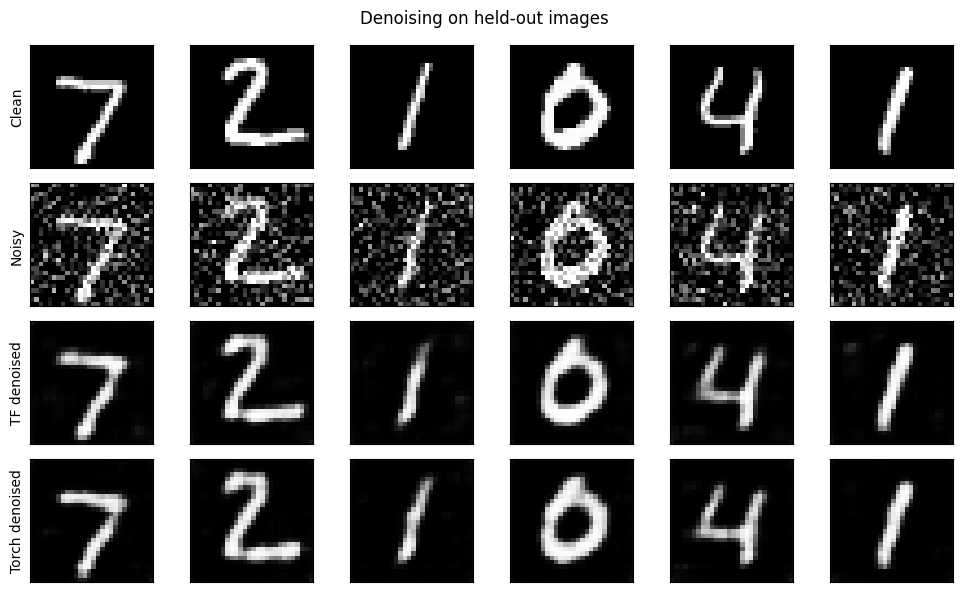

In [11]:
denoised_tf=autoencoder_tf.predict(noisy_test[...,None],batch_size=128,verbose=0)[...,0]
autoencoder_pt.eval()
with torch.no_grad(): denoised_pt=autoencoder_pt(torch.from_numpy(noisy_test[:,None])).numpy()[:,0]
for name,images in [('Noisy input',noisy_test),('TF denoised',denoised_tf),('Torch denoised',denoised_pt)]:
    print(name,'test MSE to clean target:',np.mean((images-x_test)**2))
fig,axes=plt.subplots(4,6,figsize=(10,6))
for row,(name,images) in enumerate([('Clean',x_test),('Noisy',noisy_test),('TF denoised',denoised_tf),('Torch denoised',denoised_pt)]):
    for i in range(6):
        axes[row,i].imshow(images[i],cmap='gray',vmin=0,vmax=1); axes[row,i].set_xticks([]); axes[row,i].set_yticks([])
    axes[row,0].set_ylabel(name)
plt.suptitle('Denoising on held-out images'); plt.tight_layout(); plt.show()

## ۹. ذخیره و استفادهٔ مدل

فایل‌های زیر مدل‌های مرحلهٔ دوم، یعنی denoising را ذخیره می‌کنند.
برای یک عکس جدید، همان مقیاس صفر تا یک و محور batch و channel را نگه دارید.

In [12]:
folder=root/'artifacts'/'12_autoencoder'; folder.mkdir(parents=True,exist_ok=True)
autoencoder_tf.save(folder/'denoising_tf.keras')
torch.save(autoencoder_pt.state_dict(),folder/'denoising_torch.pt')
loaded_tf=tf.keras.models.load_model(folder/'denoising_tf.keras')
np.testing.assert_allclose(loaded_tf(noisy_test[:1,...,None]).numpy()[0,...,0],denoised_tf[0],atol=1e-5)
print('Saved TF and Torch denoising models. TF load-and-predict check passed.')

Saved TF and Torch denoising models. TF load-and-predict check passed.


## ۱۰. نکته‌ها و تمرین

- کوچکی latent به تنهایی تضمین نمایش خوب نیست؛ اندازه و تعداد کانال را با کیفیت بازسازی بسنجید.
- بازسازی خوب روی MNIST به معنی توانایی بازسازی هر تصویر دیگری نیست.
- Autoencoder عادی با Variational Autoencoder فرق دارد؛ این درس مدل احتمالاتی مولد VAE نمی‌سازد.
- برای حذف نویز واقعی باید نوع نویز و دادهٔ آموزشی به مسئلهٔ واقعی نزدیک باشد.

**تمرین:** تعداد کانال latent را از ۸ به ۴ کاهش دهید و MSE و ظاهر بازسازی را مقایسه کنید.
در PyTorch ورودی اولین ConvTranspose را نیز ۴ قرار دهید.

## منابع رسمی


- [نمونهٔ convolutional autoencoder در Keras](https://keras.io/examples/vision/autoencoder/)
- [Conv2DTranspose](https://keras.io/api/layers/convolution_layers/convolution2d_transpose/)
- [ConvTranspose2d در PyTorch](https://docs.pytorch.org/docs/2.9/generated/torch.nn.ConvTranspose2d.html)


بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.